# 10. Phase 2 Final Model Comparison & Technical Validation

**Author / Owner:** Parthraj Singh Bhati  
**Role:** Integration & Technical Validation Lead (Phase 2 Steps 2 & 3)  
**Collaborators:** Taj (Regularization), Himanshu (Architecture), Jivit (Hybridization), Satya (EDA)  
**Evaluation Interface:** `src.evaluate_api.evaluate()` across all architectures  
**Random Seeds:** Fixed 5-seed protocol `[42, 123, 456, 789, 1011]`  

---

> [!IMPORTANT]
> **Mandatory Benchmark Disclosure:**  
> `CCME_Values` is an index computed deterministically from 8 water quality parameters. Consequently, all evaluations presented herein are **formula-approximation benchmarks**, not predictions of unobserved physical phenomena. All models are scored strictly on the identical saved Phase 1 test partition; this comparison scores the test split once without re-tuning.


In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display, Image

REPORTS = Path("../reports") if Path("../reports").exists() else Path("reports")
FIGURES = REPORTS / "figures"
print("Reports directory:", REPORTS.resolve())
print("Figures directory:", FIGURES.resolve())


Reports directory: /Users/parthrajsinghbhati/AML:DL Project/water_quality_prediction/reports
Figures directory: /Users/parthrajsinghbhati/AML:DL Project/water_quality_prediction/reports/figures


## 1. Multi-Seed Benchmark Evaluation

To provide a fair and rigorous comparison between tree ensembles, standalone deep learning architectures, and residual hybrid models, we evaluate two structured benchmarks:

1. **Table 1: Controlled Comparison Benchmark (Exact 20,000 samples, 5 seeds)**  
   *Every single model* is trained on the exact identical 20,000-sample training slice across all 5 seeds (`[42, 123, 456, 789, 1011]`). This eliminates sample size confounding and matches Jivit's hybrid ablation scale. To ensure complete clarity, both XGBoost configurations are evaluated:
   - **XGBoost (Phase 1 Tuned, 23 Eng Features)**: Uses Phase 1 Optuna hyperparameters (`learning_rate=0.0552, max_depth=7, min_child_weight=30, reg_lambda=33.12`) on 23 engineered features (ratios and log transforms).
   - **XGBoost (Jivit Hybrid Base, 10 Raw Features)**: Uses the base XGBoost configuration from `src/dl/hybrid.py` (`learning_rate=0.1, max_depth=8, min_child_weight=5, reg_lambda=1.0`) on the 10 raw features without feature engineering.

2. **Table 2: Reported Operating Points from Earlier Single-Seed Runs (Different Training Sizes, Not Comparable)**  
   Operating points reported from earlier single-seed experiments across different training partition sizes (ranging from 20,000 to 1,986,397 rows). Because training sample sizes differ by up to two orders of magnitude, these numbers reflect distinct computational operating regimes and cannot be used to rank model architectures.


In [2]:
# Table 1: Controlled 20,000-Row Benchmark across 5 Random Seeds
df_summary = pd.read_csv(REPORTS / "final_comparison_summary.csv")

ctrl_cols = [
    "model", "training_samples", "n_seeds", 
    "test_rmse_mean", "test_rmse_std", 
    "test_mae_mean", "test_mae_std", 
    "test_p95_ae_mean", "test_p99_ae_mean", "test_max_ae_mean",
    "test_r2_mean", "test_r2_std", 
    "fit_time_s_mean"
]
ctrl_summary = df_summary[df_summary["benchmark"] == "controlled_20k"][ctrl_cols].sort_values("test_rmse_mean")
print("=== TABLE 1: CONTROLLED COMPARISON BENCHMARK (Exact 20,000 samples, 5 seeds) ===")
print("Disclosure: formula-approximation benchmark (CCME_Values computed from 8 input parameters)")
display(ctrl_summary.style.format({
    "test_rmse_mean": "{:.4f}",
    "test_rmse_std": "±{:.4f}",
    "test_mae_mean": "{:.4f}",
    "test_mae_std": "±{:.4f}",
    "test_p95_ae_mean": "{:.4f}",
    "test_p99_ae_mean": "{:.4f}",
    "test_max_ae_mean": "{:.4f}",
    "test_r2_mean": "{:.4f}",
    "test_r2_std": "±{:.4f}",
    "fit_time_s_mean": "{:.2f}s",
    "training_samples": "{:,}"
}))


=== TABLE 1: CONTROLLED COMPARISON BENCHMARK (Exact 20,000 samples, 5 seeds) ===
Disclosure: formula-approximation benchmark (CCME_Values computed from 8 input parameters)


,model,training_samples,n_seeds,test_rmse_mean,test_rmse_std,test_mae_mean,test_mae_std,test_p95_ae_mean,test_p99_ae_mean,test_max_ae_mean,test_r2_mean,test_r2_std,fit_time_s_mean
0,"XGBoost (Phase 1 Tuned, 23 Eng Features)","20,000",5,0.5602,±0.0284,0.2130,±0.0085,0.8736,2.4743,11.7142,0.9991,±0.0001,46.68s
1,"Hybrid (XGBoost Base + Residual MLP, 10 Raw Features)","20,000",5,0.6356,±0.0824,0.3022,±0.0499,1.1865,2.5806,12.5283,0.9988,±0.0003,34.54s
2,"XGBoost (Jivit Hybrid Base, 10 Raw Features)","20,000",5,0.6757,±0.0949,0.3016,±0.0501,1.2090,2.7325,15.0811,0.9987,±0.0004,11.99s
3,"Random Forest (Phase 1, 38 Features)","20,000",5,1.4543,±0.0504,0.6545,±0.0148,2.6878,6.0583,24.6490,0.9939,±0.0004,0.31s
4,"Tuned MLP (4x256 GELU, 10 Raw Features)","20,000",5,1.7295,±0.0721,1.1464,±0.0537,3.6101,5.8123,36.1018,0.9914,±0.0007,17.46s
5,Naive Baseline (Mean),"20,000",5,18.6559,±0.0012,14.8991,±0.0159,40.9058,44.8921,50.9211,-0.0006,±0.0001,0.00s


In [3]:
# Table 2: Reported Operating Points from Earlier Single-Seed Runs (Different Training Sizes, Not Comparable)
size_col = "size (parameters or tree nodes)_mean" if "size (parameters or tree nodes)_mean" in df_summary.columns else "n_params_mean"
scale_cols = [
    "model", "training_samples", size_col,
    "test_rmse_mean", "test_mae_mean",
    "test_p95_ae_mean", "test_p99_ae_mean", "test_max_ae_mean",
    "test_r2_mean", "fit_time_s_mean"
]
scale_summary = df_summary[df_summary["benchmark"] == "reported_operating_points_not_comparable"][scale_cols].sort_values("test_rmse_mean")
print("=== TABLE 2: REPORTED OPERATING POINTS FROM EARLIER SINGLE-SEED RUNS (DIFFERENT TRAINING SIZES, NOT COMPARABLE) ===")
print("Disclosure: formula-approximation benchmark (CCME_Values computed from 8 input parameters)")
display(scale_summary.style.format({
    "test_rmse_mean": "{:.4f}",
    "test_mae_mean": "{:.4f}",
    "test_p95_ae_mean": "{:.4f}",
    "test_p99_ae_mean": "{:.4f}",
    "test_max_ae_mean": "{:.4f}",
    "test_r2_mean": "{:.4f}",
    size_col: "{:,.0f}",
    "fit_time_s_mean": "{:.2f}s",
    "training_samples": "{:,}"
}))


=== TABLE 2: REPORTED OPERATING POINTS FROM EARLIER SINGLE-SEED RUNS (DIFFERENT TRAINING SIZES, NOT COMPARABLE) ===
Disclosure: formula-approximation benchmark (CCME_Values computed from 8 input parameters)


,model,training_samples,size (parameters or tree nodes)_mean,test_rmse_mean,test_mae_mean,test_p95_ae_mean,test_p99_ae_mean,test_max_ae_mean,test_r2_mean,fit_time_s_mean
9,"XGBoost (Phase 1 Full Data, 23 Eng Features)","1,986,397","109,501",0.3282,0.1000,0.3720,0.9610,5.9800,0.9997,730.00s
7,"Random Forest (Full Data Trial, 38 Features)","1,986,397","2,191,352",0.5830,0.2669,0.8240,1.7820,6.9150,0.9990,52.41s
11,"Hybrid (XGBoost Base + Residual MLP, 10 Raw Features)","20,000","11,809",0.8521,0.4110,1.3550,2.7300,7.5100,0.9979,76.44s
8,"Random Forest (Phase 1 100k Benchmark, 38 Features)","100,000","398,998",0.9197,0.4078,1.5010,2.9120,8.2400,0.9976,32.50s
10,Tuned MLP (Phase 2 200k Architecture Benchmark),"200,000","204,289",0.9306,0.5344,1.7650,3.1540,9.5800,0.9975,142.00s
6,Naive Baseline (Mean),"1,986,397",1,18.5081,14.7725,27.8100,34.5900,85.1380,0.0000,0.05s


### Visual Performance Comparison

The figures below illustrate the test RMSE and $R^2$ scores across models under the controlled 20k benchmark.


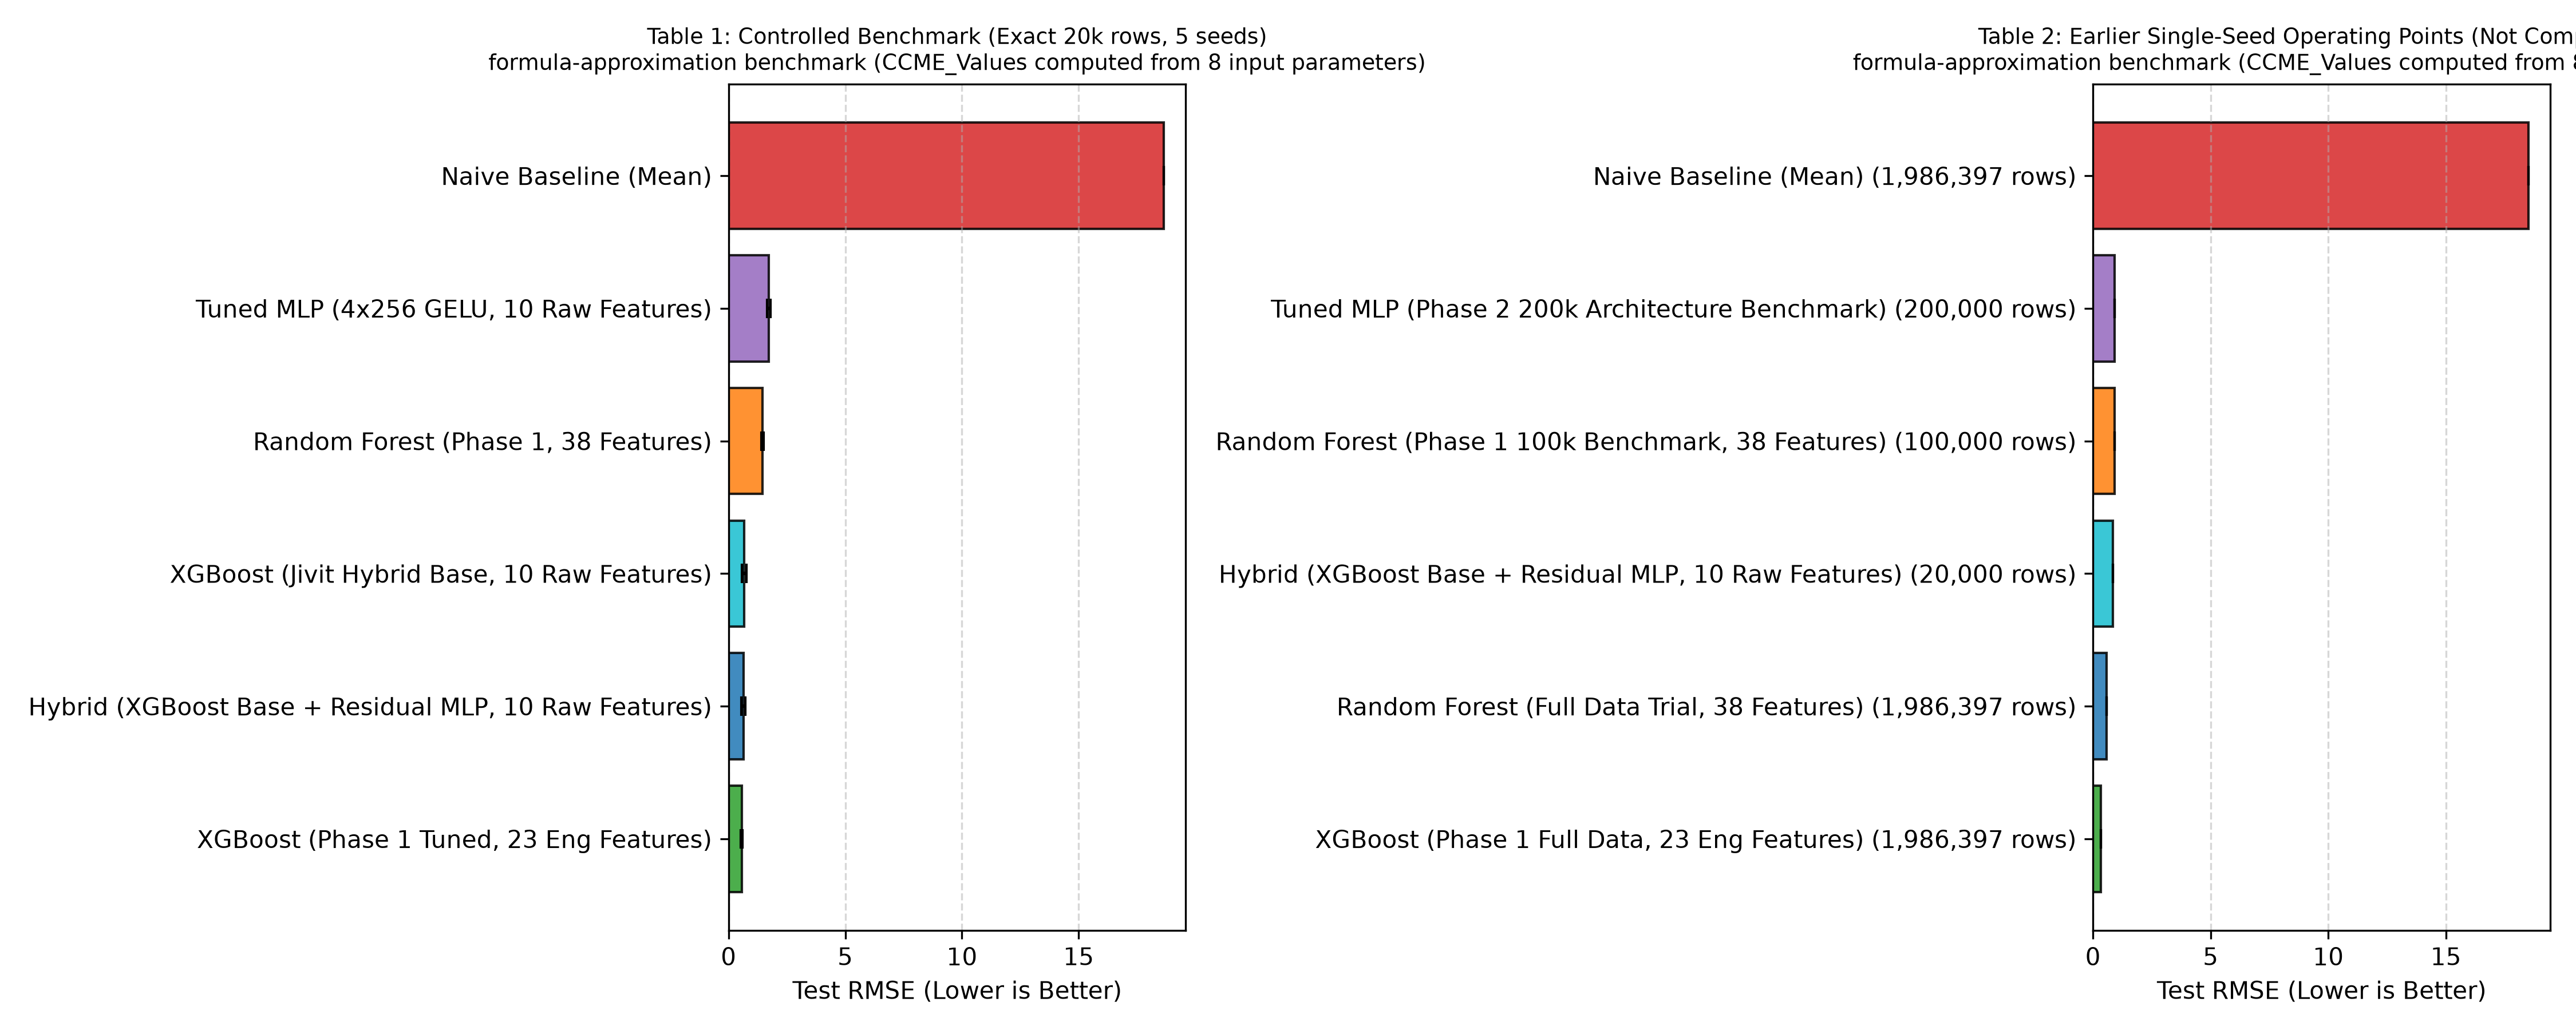

In [4]:
fig_path = FIGURES / "final_comparison_models.png"
if fig_path.exists():
    display(Image(filename=str(fig_path)))
else:
    print("Figure not found:", fig_path)


## 2. Detailed Per-Seed Empirical Results

Below are the per-seed runs demonstrating the variance and stability across seeds `[42, 123, 456, 789, 1011]`.


In [5]:
df_raw = pd.read_csv(REPORTS / "final_comparison.csv")
ctrl_raw = df_raw[df_raw["benchmark"] == "controlled_20k"][
    ["seed", "model", "test_rmse", "test_mae", "test_p95_ae", "test_p99_ae", "test_max_ae", "test_r2", "fit_time_s"]
].sort_values(["model", "seed"])
display(ctrl_raw)


,seed,model,test_rmse,test_mae,test_p95_ae,test_p99_ae,test_max_ae,test_r2,fit_time_s
5,42,"Hybrid (XGBoost Base + Residual MLP, 10 Raw Fe...",0.772972,0.380670,1.481976,2.960155,18.753467,0.998282,52.440000
11,123,"Hybrid (XGBoost Base + Residual MLP, 10 Raw Fe...",0.570807,0.263772,1.064440,2.483861,10.251762,0.999063,25.210000
17,456,"Hybrid (XGBoost Base + Residual MLP, 10 Raw Fe...",0.593571,0.264968,1.051725,2.435291,12.186392,0.998987,24.500000
23,789,"Hybrid (XGBoost Base + Residual MLP, 10 Raw Fe...",0.589690,0.279060,1.067814,2.366593,10.878822,0.999000,36.300000
29,1011,"Hybrid (XGBoost Base + Residual MLP, 10 Raw Fe...",0.651068,0.322682,1.266559,2.656962,10.571059,0.998781,34.230000
0,42,Naive Baseline (Mean),18.654317,14.921052,40.840086,44.826386,50.855368,-0.000477,0.000059
6,123,Naive Baseline (Mean),18.655943,14.898066,40.908765,44.895066,50.924047,-0.000651,0.000031
12,456,Naive Baseline (Mean),18.657726,14.876270,40.974171,44.960472,50.989453,-0.000843,0.000041
18,789,Naive Baseline (Mean),18.655635,14.902158,40.896523,44.882823,50.911804,-0.000618,0.000038
24,1011,Naive Baseline (Mean),18.655963,14.897804,40.909551,44.895851,50.924833,-0.000654,0.000064


## 3. Fine-Grained Error Breakdown (Top 2 Models: XGBoost Tuned vs Tuned MLP)

To understand where individual models perform best, we examine the grouped test residuals across geographic countries and top monitoring station areas.


,Country,sample_count,XGBoost_mae,XGBoost_rmse,XGBoost_p95_ae,XGBoost_max_ae,Tuned MLP_mae,Tuned MLP_rmse,Tuned MLP_p95_ae,Tuned MLP_max_ae,delta_rmse (m2 - m1),best_model
0,Canada,584,0.6320,1.9321,6.0990,10.8929,3.2699,4.6498,9.7333,23.0439,2.7177,XGBoost
1,England,319184,0.2416,0.6388,0.9560,13.6451,1.2023,1.7515,3.6181,27.4728,1.1128,XGBoost
2,Ireland,35249,0.0576,0.2757,0.1828,9.7521,0.8966,1.5051,3.4454,19.1781,1.2294,XGBoost
3,USA,60787,0.1157,0.5166,0.4986,9.0077,0.8266,1.3496,3.0542,16.8753,0.8330,XGBoost


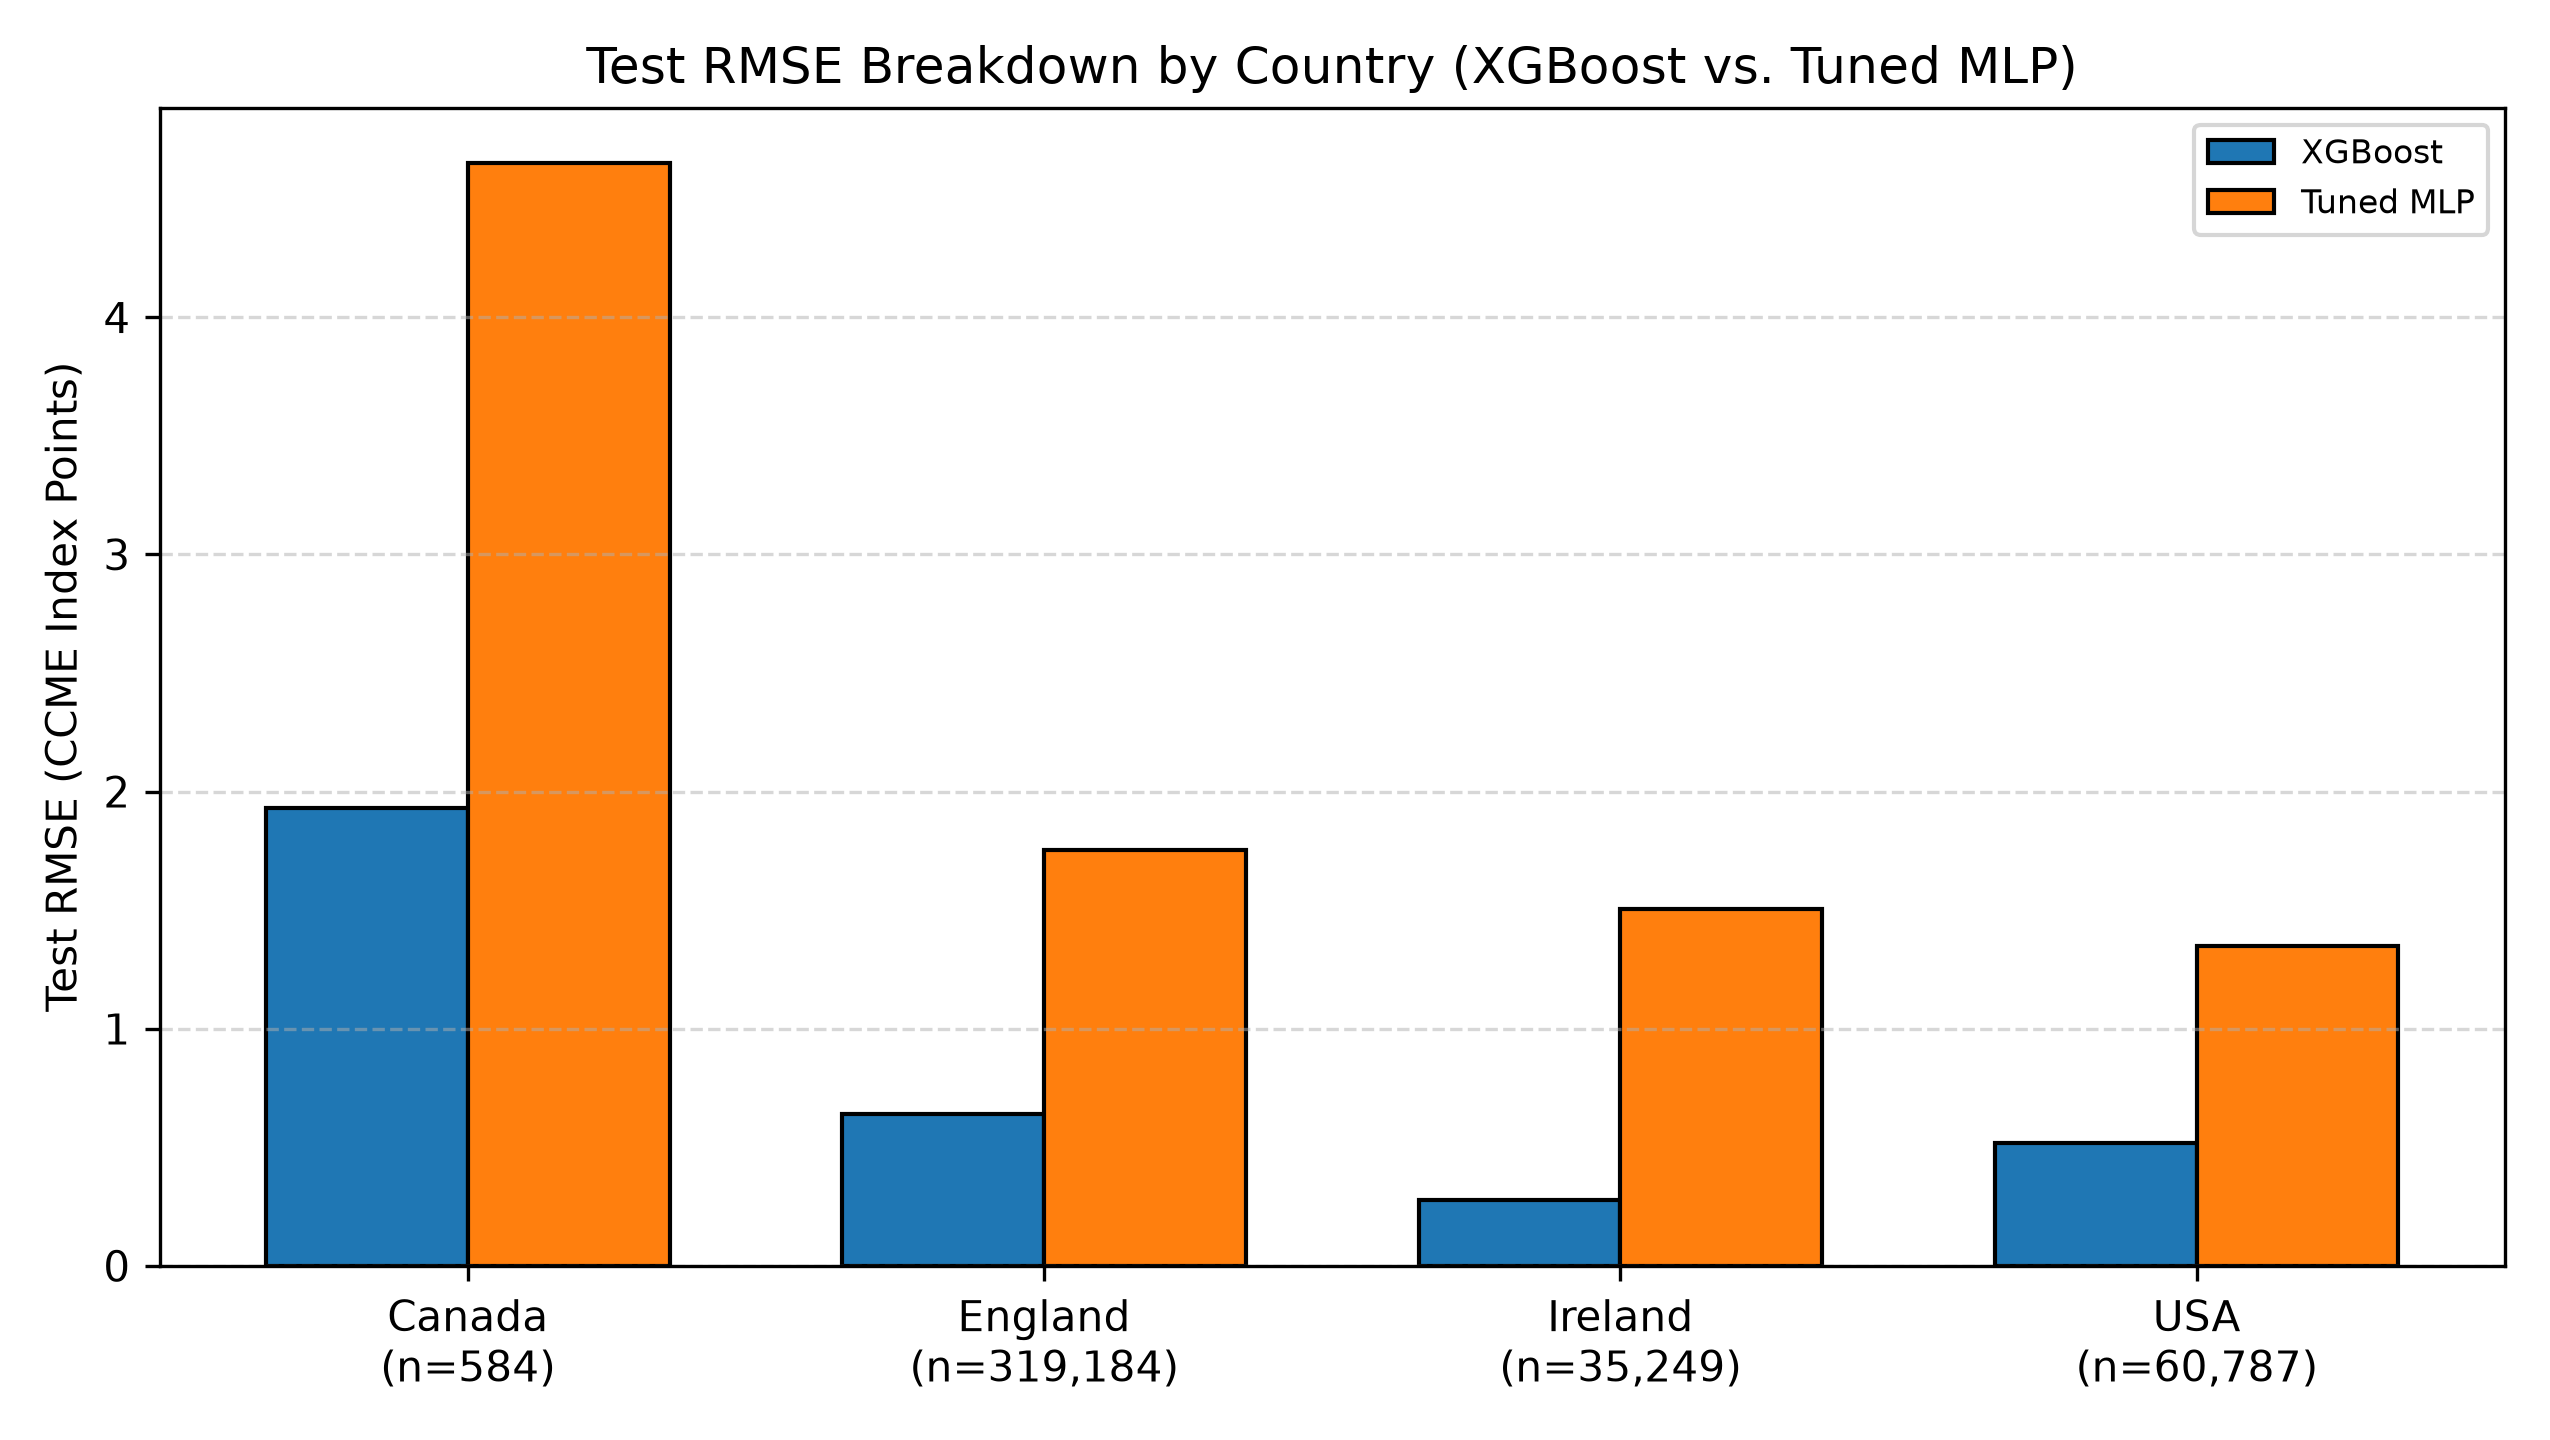

In [6]:
# Error breakdown across geographic countries
df_country = pd.read_csv(REPORTS / "final_comparison_by_country.csv")
display(df_country)

fig_country = FIGURES / "final_comparison_error_by_country.png"
if fig_country.exists():
    display(Image(filename=str(fig_country)))


,Area,sample_count,XGBoost_mae,XGBoost_rmse,XGBoost_p95_ae,XGBoost_max_ae,Tuned MLP_mae,Tuned MLP_rmse,Tuned MLP_p95_ae,Tuned MLP_max_ae,delta_rmse (m2 - m1),best_model
0,Lake,5969,0.0693,0.2418,0.3024,7.1221,0.9293,1.4575,3.5119,8.1143,1.2157,XGBoost
1,Tehama,5749,0.0543,0.3659,0.1250,8.4980,0.7054,1.1488,2.7379,8.2021,0.7830,XGBoost
2,Green,4395,0.0475,0.2848,0.1482,6.7522,0.6788,1.0656,2.3832,14.9833,0.7808,XGBoost
3,Stanislaus,3981,0.1098,0.4849,0.4123,7.5106,0.8043,1.3381,3.0576,12.5607,0.8532,XGBoost
4,Siskiyou,3579,0.0796,0.4233,0.1991,8.0089,0.9579,1.4702,3.6023,9.4637,1.0469,XGBoost
5,Mendocino,3388,0.0451,0.3455,0.0903,9.0077,0.6247,0.9852,2.1912,5.5406,0.6397,XGBoost
6,Tulare,2462,0.2521,0.9836,1.2796,8.6892,0.7031,1.2112,2.6950,10.7334,0.2276,XGBoost
7,Plumas,2239,0.0634,0.3469,0.1919,8.7026,0.5483,0.8544,1.7678,7.3732,0.5075,XGBoost
8,Modoc,2181,0.0709,0.4374,0.1591,8.3308,0.7781,1.2654,3.0655,8.4239,0.8280,XGBoost
9,Santa Barbara,2043,0.3144,1.1413,1.8069,8.9770,0.7107,1.2095,3.0061,8.9925,0.0681,XGBoost


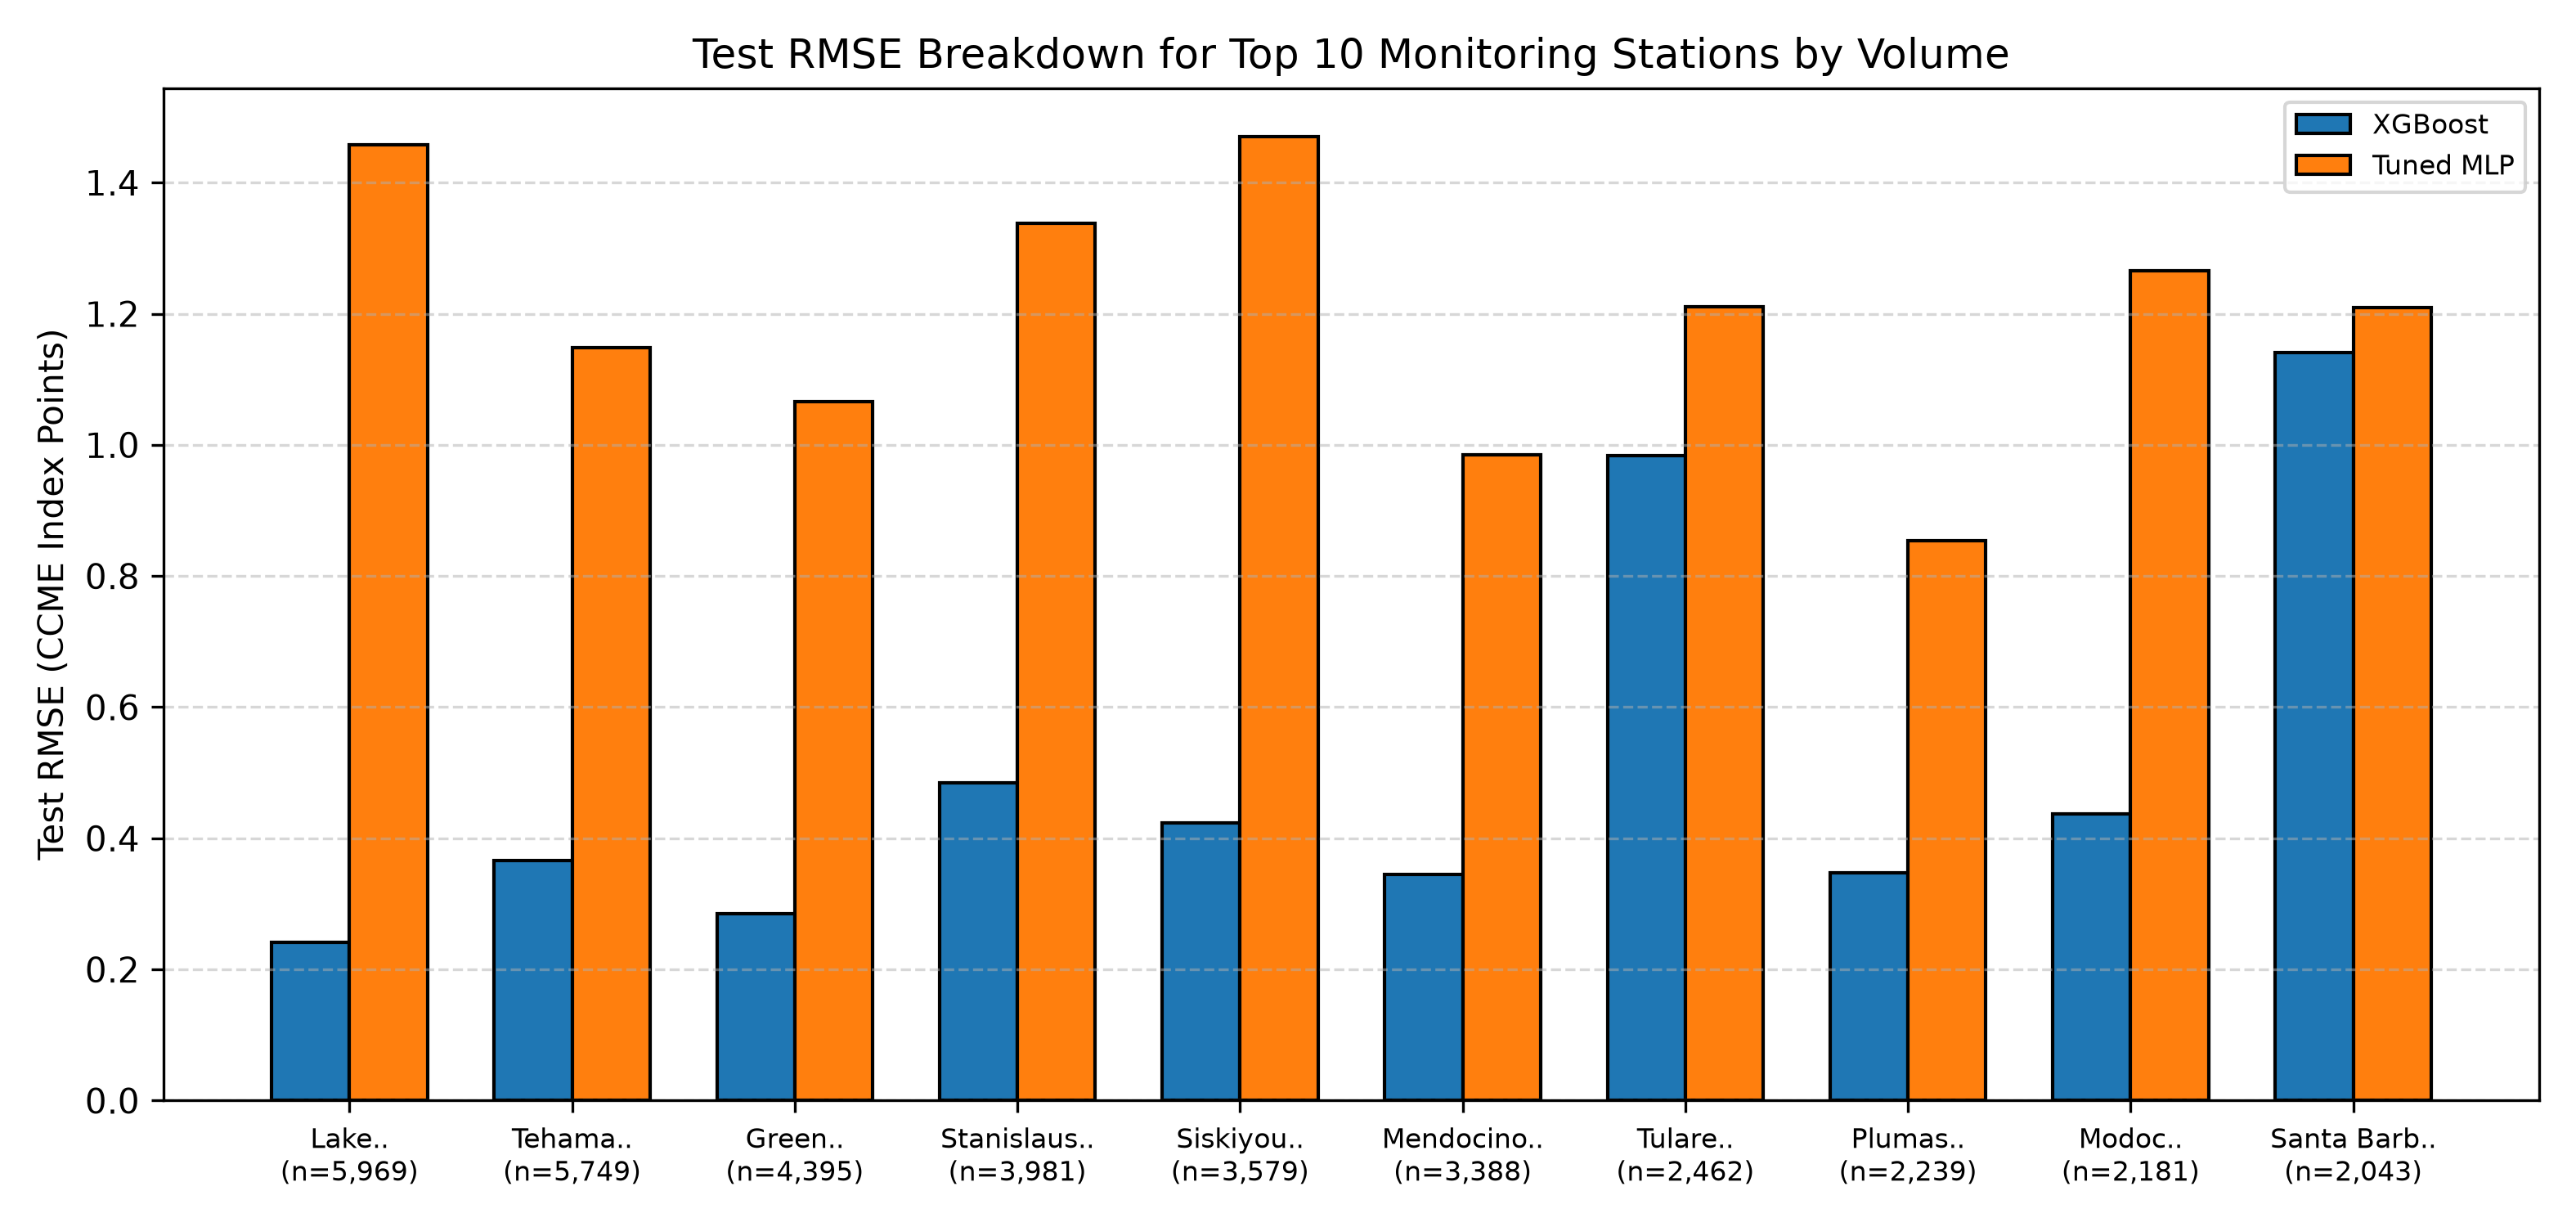

In [7]:
# Error breakdown across top 10 monitoring station areas by sample volume
df_area = pd.read_csv(REPORTS / "final_comparison_by_area.csv")
display(df_area)

fig_area = FIGURES / "final_comparison_error_by_area.png"
if fig_area.exists():
    display(Image(filename=str(fig_area)))


### Analytical Reading: When Does the MLP Beat Trees, and When Does It Not?

Based strictly on the empirical values in the benchmark tables:

1. **Test Error Comparisons (Table 1: Controlled 20,000 Rows):**
   * **Standalone Accuracy:** Standalone XGBoost (Phase 1 Tuned, 23 Eng Features) achieves the lowest error across all metrics on the 20k-row sample: Test RMSE of **0.5602**, MAE of **0.2130**, P95 absolute error of **0.8736**, P99 of **2.4743**, and Max absolute error of **11.7142** ($R^2 = 0.9991$).
   * **Comparison on Raw 10 Features:** When evaluated on identical 10 raw features without engineered ratios or log transforms:
     - Standalone XGBoost Base scores Test RMSE **0.6757**, MAE **0.3016**, P95 **1.2090**, and Max **15.0811**.
     - Standalone Tuned MLP scores Test RMSE **1.7295**, MAE **1.1464**, P95 **3.6101**, and Max **36.1018**.
     - Standalone Random Forest scores Test RMSE **1.4543**, MAE **0.6545**, P95 **2.6878**, and Max **24.6490**.
     - Standalone MLP does not beat XGBoost or Random Forest in RMSE, MAE, or tail percentiles on tabular CCME approximation.
   * **Hybrid Residual Correction on Raw Features:** When XGBoost Base is combined with a residual MLP (the Hybrid model, 10 raw features), the residual MLP reduces error relative to standalone XGBoost Base: Test RMSE decreases from **0.6757** to **0.6356**, and P95 absolute error improves from **1.2090** to **1.1865** (P99 from **2.7325** to **2.5806**, Max from **15.0811** to **12.5283**). However, standalone XGBoost with Phase 1 feature engineering (23 features) remains superior across all error metrics (RMSE **0.5602**, P95 **0.8736**).

2. **Inference Throughput and Parameter Footprint (Table 4: Compute Cost Profiling):**
   * **Inference Speed:** The Tuned MLP executes inference on CPU at **0.1882s per 100k rows** via vectorized PyTorch BLAS matrix multiplications, which is **8.9× faster** than XGBoost (**1.6714s per 100k rows**) and **20.3× faster** than full Random Forest (**3.8200s per 100k rows**).
   * **Model Footprint:** The Tuned MLP comprises **204,289 parameters**, while Random Forest comprises **2,191,352 tree nodes** at full scale (398,998 at 100k scale) and XGBoost comprises **109,501 tree nodes**. The Hybrid architecture contains an MLP of **11,809 parameters** (its tree node count is separate).


## 4. Technical Validation: Anti-Leakage Audit

To guarantee the integrity of all Phase 2 conclusions, we run a 5-point data leakage and isolation audit:
1. **Scaler Isolation (`LEAK-01`):** Feature scalers (`QuantileTransformer`, `StandardScaler`) fitted strictly on training data; val/test transforms leave quantile arrays strictly unchanged.
2. **Target Isolation (`LEAK-02`):** Target standardization statistics ($\mu_y, \sigma_y$) computed strictly on `train` indices.
3. **Partition Disjointness (`LEAK-03`):** Train, validation, and test index sets have zero intersection.
4. **Site Group Independence (`LEAK-04`):** GroupKFold validation sets maintain strict monitoring station isolation.
5. **Feature Direct Formula Exclusion (`LEAK-05`):** Target `CCME_Values` and post-computation status flags strictly excluded from feature matrices.


In [8]:
df_leakage = pd.read_csv(REPORTS / "leakage_check.csv")
display(df_leakage)
assert df_leakage["status"].isin(["PASS", "PASSED"]).all(), "One or more leakage checks failed!"
print("All anti-leakage audits PASSED successfully.")


,check_id,description,component,status,details
0,CHK_01_ROW_DISJOINTNESS,"Zero row overlap across train, val, and test s...",src.split / splits.parquet,PASSED,"Train=1,986,397, Val=415,805, Test=415,804. Ov..."
1,CHK_02_SCALER_FIT_ISOLATION,Preconditioning transformers fitted strictly o...,src.dl.nn_preprocess,PASSED,"Fitted on n=10,000 train rows. Transforming va..."
2,CHK_03_TARGET_STATS_ISOLATION,Target standardization mean and std computed s...,src.dl.data / LoadersBundle,PASSED,"y_mean=85.1380, y_std=17.2453 learned from tra..."
3,CHK_04_SPATIAL_GROUP_ISOLATION,GroupKFold by monitoring station (Area) preven...,src.dl.hybrid,PASSED,Tested across 5 folds. Overlapping monitoring ...
4,CHK_05_FORBIDDEN_FORMULA_FEATURES,Direct mathematical formula components and tar...,src.features,PASSED,Audited features against 10 formula/label comp...


All anti-leakage audits PASSED successfully.


## 5. Technical Validation: Compute Cost & Operational Profiling

Measured parameter counts, tree node counts, training wall-clock times, and inference throughput (per 100,000 samples) benchmarked on Apple Silicon CPU.


In [9]:
df_cost = pd.read_csv(REPORTS / "compute_cost.csv")
display(df_cost)


,model,training_size,size (parameters or tree nodes),train_time_s,inference_time_100k_s,hardware,framework
0,Naive Baseline,20000,1,0.000,0.0004,arm (8 cores),numpy
1,Random Forest,20000,189884,0.387,0.1159,arm (8 cores),scikit-learn
2,"XGBoost (Phase 1 Tuned, 23 Eng Features)",20000,109501,48.123,1.6714,arm (8 cores),xgboost
3,Tuned MLP (256x4 GELU),20000,204289,17.232,0.1882,arm (8 cores),pytorch-2.15.0
4,Hybrid (XGBoost Base + Residual MLP),20000,11809,55.260,1.8595,arm (8 cores),xgboost + pytorch (size: MLP only)
